# Stock Price Direction Prediction: MLP vs LSTM

**Name:** Yash Verdhan Parihar  **Reg no:** 12402424

## 1. Aim
Predict whether the next trading session's adjusted closing price will go UP or DOWN using the previous 20 sessions.
UP means a higher close; DOWN includes an unchanged close. Both models use the same data and features.



In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
from IPython.display import display

TICKERS = ["SPY", "AAPL", "MSFT"]
START_DATE = "2010-01-01"
END_DATE = "2026-01-01"
LOOKBACK = 20
EPOCHS = 25
BATCH_SIZE = 128

keras.utils.set_random_seed(42)
sns.set_theme(style="whitegrid")
gpus = tf.config.list_physical_devices("GPU")
device = "/GPU:0" if gpus else "/CPU:0"
print("Training device:", device)
from sklearn.metrics import roc_curve
from IPython.display import Markdown


Training device: /GPU:0


## 2. Data and cleaning
Download daily OHLCV data for 2010 to 2025. The end date is exclusive, so no 2026 observations are included.
Prices are adjusted for dividends and stock splits. Duplicate dates are removed and invalid bars are marked as missing.
Missing prices are not filled in. Windows containing missing values are excluded, while valid large price changes are kept.

In [2]:
price_columns = ["Open", "High", "Low", "Close", "Volume"]
prices = {}
data_summary = []

for ticker in TICKERS:
    try:
        data = yf.download(ticker, start=START_DATE, end=END_DATE,
                           auto_adjust=True, progress=False, threads=False)
        if data.empty:
            raise ValueError("No data returned")
        if isinstance(data.columns, pd.MultiIndex):
            data.columns = data.columns.get_level_values(0)
        data = data[price_columns].copy()
        data.index = pd.DatetimeIndex(data.index).tz_localize(None)
        data = data.sort_index()
        data = data.loc[~data.index.duplicated(keep="last")]
        data = data.loc[(data.index >= START_DATE) & (data.index < END_DATE)]
        data = data.replace([np.inf, -np.inf], np.nan)

        invalid = data.isna().any(axis=1) | (data <= 0).any(axis=1)
        invalid |= data["High"] < data[["Open", "Close", "Low"]].max(axis=1)
        invalid |= data["Low"] > data[["Open", "Close", "High"]].min(axis=1)
        data.loc[invalid, price_columns] = np.nan
        if data["Close"].notna().sum() < 100:
            raise ValueError("Not enough valid history")

        prices[ticker] = data
        data_summary.append([ticker, data.index.min().date(),
                             data.index.max().date(), len(data), int(invalid.sum())])
    except Exception as error:
        print(f"{ticker}: {error}")

if len(prices) < 3:
    raise ValueError("At least three assets are required. Check the connection and rerun.")

# Keep missing sessions visible when combining the assets.
all_dates = pd.DatetimeIndex([])
for data in prices.values():
    all_dates = all_dates.union(data.index)
for ticker in prices:
    prices[ticker] = prices[ticker].reindex(all_dates.sort_values())

display(pd.DataFrame(data_summary, columns=["Asset", "First date", "Last date",
                                           "Rows", "Invalid or missing bars"]))

,Asset,First date,Last date,Rows,Invalid or missing bars
0,SPY,2010-01-04,2025-12-31,4024,1
1,AAPL,2010-01-04,2025-12-31,4024,1
2,MSFT,2010-01-04,2025-12-31,4024,1


## 3. Features
Use ten features: daily return, previous return, opening gap, daily range, three moving-average ratios, RSI, volume change and volatility.
Ratios make stocks with different prices easier to compare. Each feature uses only current or earlier observations.
The target is 1 when the next session's adjusted close is higher, otherwise 0. The final row has no known target.

,return,previous_return,opening_gap,daily_range,ma5_ratio,ma10_ratio,ma20_ratio,rsi,volume_change,volatility
2010-02-02,0.012104,0.015551,0.001834,0.015492,0.012233,0.004267,-0.015278,0.402380,0.151507,0.010585
2010-02-03,-0.004983,0.012104,-0.004530,0.008832,0.007190,0.002968,-0.018521,0.353873,-0.201533,0.010574
2010-02-04,-0.030866,-0.004983,-0.007739,0.024521,-0.020070,-0.023298,-0.045715,0.281971,1.065155,0.012403
2010-02-05,0.002067,-0.030866,0.001127,0.021564,-0.016723,-0.018984,-0.040504,0.310325,0.383695,0.012344
2010-02-08,-0.007219,0.002067,0.000750,0.014355,-0.018082,-0.022578,-0.043697,0.241688,-0.545840,0.012270


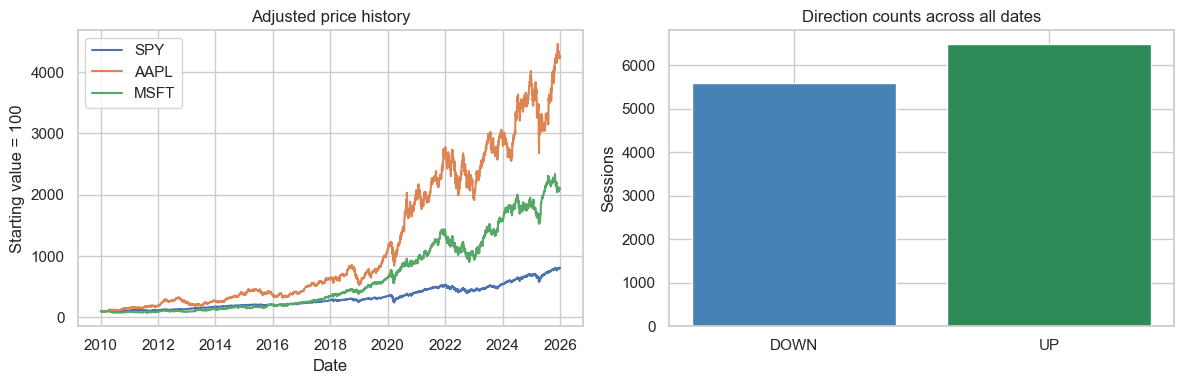

In [3]:
FEATURES = ["return", "previous_return", "opening_gap", "daily_range",
            "ma5_ratio", "ma10_ratio", "ma20_ratio", "rsi", "volume_change", "volatility"]

def make_features(data):
    close = data["Close"]
    daily_return = close.pct_change(fill_method=None)
    features = pd.DataFrame(index=data.index)
    features["return"] = daily_return
    features["previous_return"] = daily_return.shift(1)
    features["opening_gap"] = data["Open"] / close.shift(1) - 1
    features["daily_range"] = (data["High"] - data["Low"]) / close
    for days in [5, 10, 20]:
        average = close.rolling(days).mean()
        features[f"ma{days}_ratio"] = close / average - 1

    change = close.diff()
    gain = change.clip(lower=0).rolling(14).mean()
    loss = (-change.clip(upper=0)).rolling(14).mean()
    features["rsi"] = gain / (gain + loss)
    features.loc[(gain == 0) & (loss == 0), "rsi"] = 0.5
    features["volume_change"] = data["Volume"].pct_change(fill_method=None)
    features["volatility"] = daily_return.rolling(20).std()

    next_close = close.shift(-1)
    features["target"] = (next_close > close).astype(float)
    features.loc[close.isna() | next_close.isna(), "target"] = np.nan
    features["next_date"] = pd.Series(data.index, index=data.index).shift(-1)
    return features.replace([np.inf, -np.inf], np.nan)

feature_data = {}
for ticker, data in prices.items():
    feature_data[ticker] = make_features(data)

display(feature_data["SPY"][FEATURES].dropna().head())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ticker, data in prices.items():
    close = data["Close"].dropna()
    axes[0].plot(close.index, 100 * close / close.iloc[0], label=ticker)
axes[0].set(title="Adjusted price history", xlabel="Date", ylabel="Starting value = 100")
axes[0].legend()
targets = pd.concat([frame["target"].dropna() for frame in feature_data.values()])
counts = targets.value_counts().reindex([0, 1], fill_value=0)
axes[1].bar(["DOWN", "UP"], counts.values, color=["steelblue", "seagreen"])
axes[1].set(title="Direction counts across all dates", ylabel="Sessions")
plt.tight_layout()
plt.show()


## 4. Sequences, splitting and scaling
Create 20-session windows and split dates into 70% training, 15% validation and 15% testing, with the same boundaries for every asset.
A sample belongs to the date of its next-session outcome, so training targets do not reach into validation dates.
StandardScaler is fitted only on training-period feature rows. It centres and scales values; unlike min-max normalisation, it does not map them to a fixed range.

In [4]:
def make_sequences(frames):
    windows = []
    records = []
    for ticker, frame in frames.items():
        values = frame[FEATURES].to_numpy(dtype=np.float32)
        for end in range(LOOKBACK - 1, len(frame)):
            window = values[end - LOOKBACK + 1:end + 1]
            target = frame["target"].iloc[end]
            if np.isfinite(window).all() and pd.notna(target):
                windows.append(window)
                records.append([ticker, frame.index[end], frame["next_date"].iloc[end], int(target)])
    info = pd.DataFrame(records, columns=["asset", "date", "next_date", "target"])
    order = info.sort_values(["next_date", "asset"]).index.to_numpy()
    return np.array(windows)[order], info.iloc[order].reset_index(drop=True)

X, sample_info = make_sequences(feature_data)
y = sample_info["target"].to_numpy()
dates = pd.DatetimeIndex(sample_info["next_date"].unique()).sort_values()
train_end = dates[int(0.70 * len(dates)) - 1]
validation_end = dates[int(0.85 * len(dates)) - 1]

train_mask = sample_info["next_date"] <= train_end
val_mask = (sample_info["next_date"] > train_end) & (sample_info["next_date"] <= validation_end)
test_mask = sample_info["next_date"] > validation_end

training_last_date = sample_info.loc[train_mask, "date"].max()
training_rows = []
for frame in feature_data.values():
    training_rows.append(frame.loc[frame.index <= training_last_date, FEATURES].dropna())
scaler = StandardScaler()
scaler.fit(pd.concat(training_rows).to_numpy())

def scale_windows(windows):
    rows = windows.reshape(-1, len(FEATURES))
    return scaler.transform(rows).reshape(windows.shape).astype(np.float32)

X_train = scale_windows(X[train_mask])
X_val = scale_windows(X[val_mask])
X_test = scale_windows(X[test_mask])
y_train, y_val, y_test = y[train_mask], y[val_mask], y[test_mask]

print("Training ends:", train_end.date())
print("Validation ends:", validation_end.date())
print("Training, validation, test shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Training UP percentage:", round(100 * y_train.mean(), 2))

Training ends: 2021-03-29
Validation ends: 2023-08-14
Training, validation, test shapes: (8241, 20, 10) (1794, 20, 10) (1794, 20, 10)
Training UP percentage: 53.67


## 5. Models
The MLP flattens each 20-session window before using dense layers. The LSTM reads the same window in time order.
Both finish with a sigmoid output, giving an estimated probability of UP. A probability of at least 0.5 is classified as UP.
Dropout reduces overfitting. Binary cross-entropy measures prediction error, and Adam updates the weights.

```text
20 sessions with 10 features
    |-- MLP: Flatten, Dense 128, BatchNorm, Dropout, Dense 64
    |-- LSTM: LSTM 64, Dropout, Dense 32
Each model: Dense 1 with sigmoid -> UP or DOWN
```


In [5]:
def build_model(model_name):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(LOOKBACK, len(FEATURES))))
    if model_name == "MLP":
        model.add(keras.layers.Flatten())
        model.add(keras.layers.Dense(128, activation="relu"))
        model.add(keras.layers.BatchNormalization())
        model.add(keras.layers.Dropout(0.3))
        model.add(keras.layers.Dense(64, activation="relu"))
    else:
        model.add(keras.layers.LSTM(64))
        model.add(keras.layers.Dropout(0.3))
        model.add(keras.layers.Dense(32, activation="relu"))
    model.add(keras.layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

with tf.device(device):
    models = {"MLP": build_model("MLP"), "LSTM": build_model("LSTM")}
for name, model in models.items():
    print(name)
    model.summary()

MLP
Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 flatten (Flatten)           (None, 200)               0         


 dense (Dense)               (None, 128)               25728     


 batch_normalization (BatchN  (None, 128)              512       


... (15 outputs left out)

Total params: 21,313


Trainable params: 21,313


Non-trainable params: 0


_________________________________________________________________


## 6. Training
Train for up to 25 epochs with batches of 128 samples.
EarlyStopping restores the weights with the lowest validation loss. ReduceLROnPlateau lowers the learning rate when progress slows.
The test set is not used during training or early stopping.

In [6]:
histories = {}
for name, model in models.items():
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=0.00001)
    ]
    print("Training", name)
    with tf.device(device):
        history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=False,
                            callbacks=callbacks, verbose=2)
    histories[name] = history.history

Training MLP
Epoch 1/25


65/65 - 2s - loss: 0.7569 - accuracy: 0.5123 - val_loss: 0.7167 - val_accuracy: 0.4916 - lr: 0.0010 - 2s/epoch - 24ms/step


Epoch 2/25


65/65 - 0s - loss: 0.6958 - accuracy: 0.5572 - val_loss: 0.7197 - val_accuracy: 0.4861 - lr: 0.0010 - 353ms/epoch - 5ms/step


Epoch 3/25


65/65 - 0s - loss: 0.6769 - accuracy: 0.5778 - val_loss: 0.7193 - val_accuracy: 0.5084 - lr: 0.0010 - 338ms/epoch - 5ms/step


... (14 outputs left out)

Epoch 5/25


65/65 - 1s - loss: 0.6881 - accuracy: 0.5431 - val_loss: 0.6965 - val_accuracy: 0.5100 - lr: 5.0000e-04 - 567ms/epoch - 9ms/step


Epoch 6/25


65/65 - 1s - loss: 0.6873 - accuracy: 0.5450 - val_loss: 0.6962 - val_accuracy: 0.5111 - lr: 2.5000e-04 - 706ms/epoch - 11ms/step


## 7. Training curves
Plot training and validation loss and accuracy against the completed epochs for each model.
If training loss keeps falling while validation loss rises, the model may be overfitting.

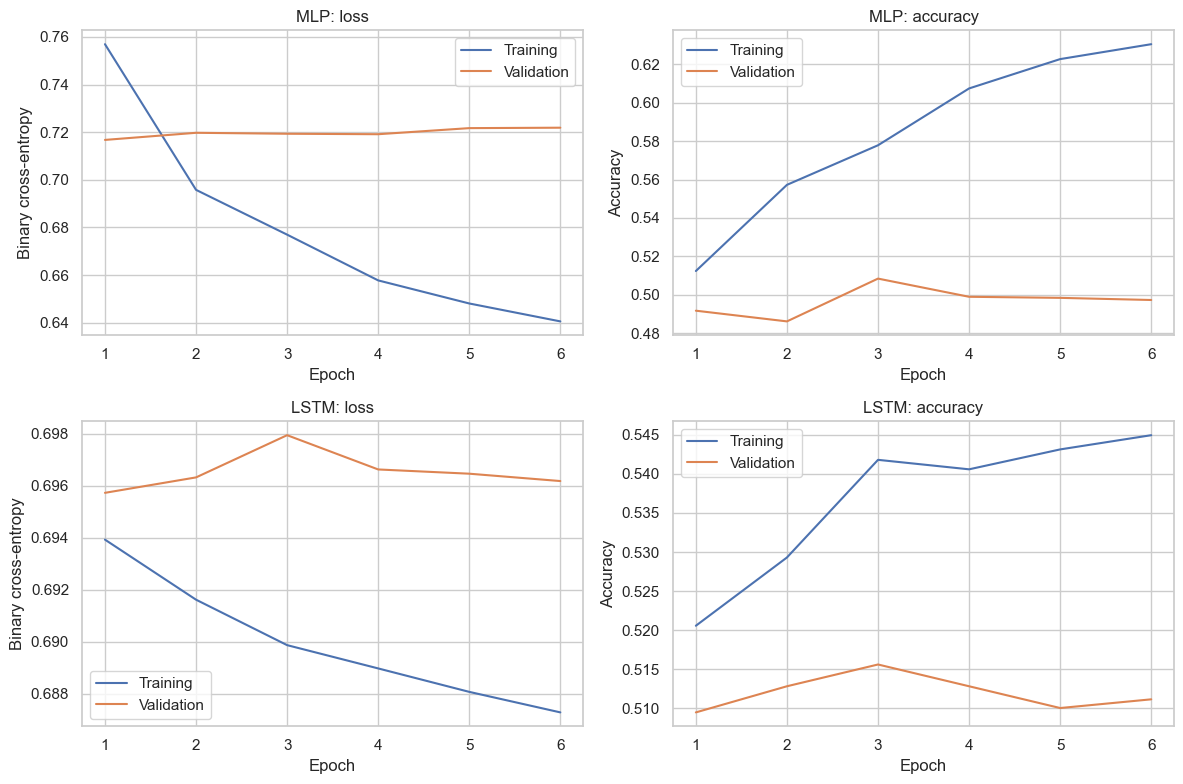

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, history) in enumerate(histories.items()):
    epochs = range(1, len(history["loss"]) + 1)
    axes[row, 0].plot(epochs, history["loss"], label="Training")
    axes[row, 0].plot(epochs, history["val_loss"], label="Validation")
    axes[row, 0].set(title=f"{name}: loss", xlabel="Epoch", ylabel="Binary cross-entropy")
    axes[row, 1].plot(epochs, history["accuracy"], label="Training")
    axes[row, 1].plot(epochs, history["val_accuracy"], label="Validation")
    axes[row, 1].set(title=f"{name}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    for axis in axes[row]:
        axis.legend()
        axis.set_xticks(list(epochs))
plt.tight_layout()
plt.show()

### Observation
Compare each model's training loss with its validation loss. A widening gap suggests overfitting.
The lowest validation loss matters more than the final training accuracy; early stopping restores that model's weights.


## 8. Test results
Compare the models with a baseline that always predicts the most common training class.
Precision measures how often predicted UP moves are correct; recall measures how many actual UP moves are found. F1 combines them.
ROC-AUC measures how well the probabilities rank UP above DOWN; a constant baseline scores 0.5 when both classes occur.

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.5585,0.5585,1.0000,0.7167,0.5000
MLP,0.5301,0.5552,0.7974,0.6546,0.4964
LSTM,0.5530,0.5566,0.9810,0.7103,0.5084


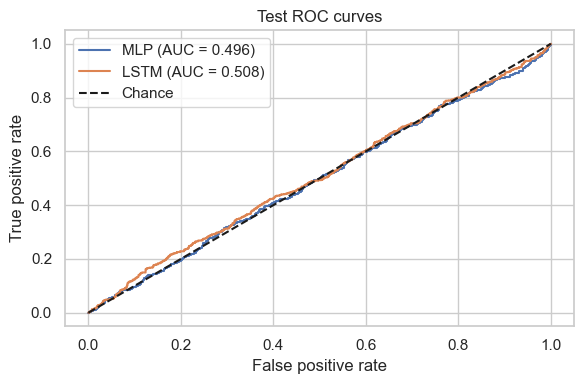

**Current run:** MLP accuracy 53.01%; LSTM accuracy 55.30%; majority baseline 55.85%.

In [8]:
def evaluate(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

test_probabilities = {"Majority baseline": np.full(len(y_test), y_train.mean())}
for name, model in models.items():
    test_probabilities[name] = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()

results = []
for name, probabilities in test_probabilities.items():
    row = evaluate(y_test, probabilities)
    row["Model"] = name
    results.append(row)
results = pd.DataFrame(results).set_index("Model")
display(results.round(4))

fig, ax = plt.subplots(figsize=(6, 4))
for name in ["MLP", "LSTM"]:
    false_positive, true_positive, _ = roc_curve(y_test, test_probabilities[name])
    auc = results.loc[name, "ROC-AUC"]
    ax.plot(false_positive, true_positive, label=f"{name} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set(title="Test ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax.legend()
plt.tight_layout()
plt.show()
display(Markdown(
    f"**Current run:** MLP accuracy {results.loc['MLP', 'Accuracy']:.2%}; "
    f"LSTM accuracy {results.loc['LSTM', 'Accuracy']:.2%}; "
    f"majority baseline {results.loc['Majority baseline', 'Accuracy']:.2%}."
))


### Observation
Compare both models with the majority baseline using the current results above. Higher accuracy is useful only in that context.
ROC curves close to the dashed line indicate weak separation between UP and DOWN, even when UP recall is high.


## 9. Confusion matrices
Rows show the actual class and columns show the predicted class. UP is class 1 and DOWN is class 0.
The matrices show whether a model predicts both directions or mostly chooses one class.

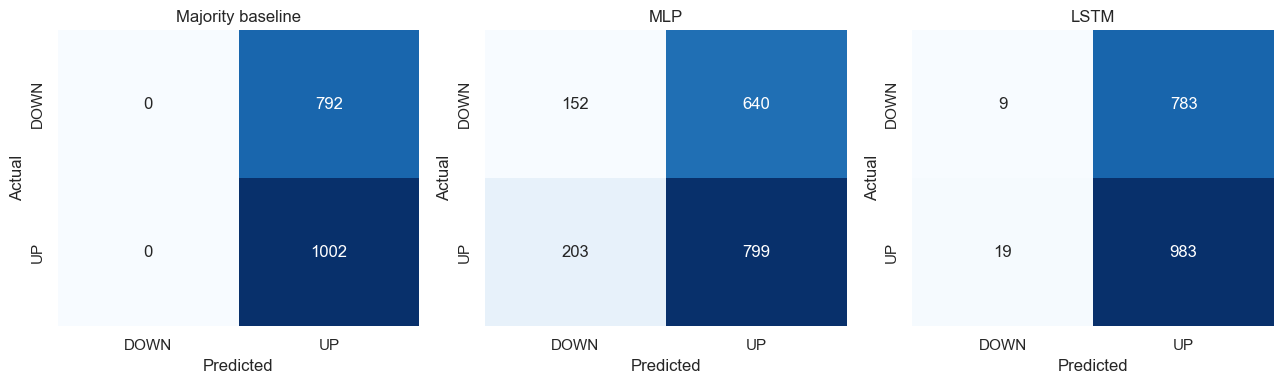

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, (name, probabilities) in zip(axes, test_probabilities.items()):
    predictions = (probabilities >= 0.5).astype(int)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=["DOWN", "UP"], yticklabels=["DOWN", "UP"])
    axis.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

### Observation
Compare correct predictions on the diagonal with mistakes off the diagonal.
A model that predicts UP almost every time may have high UP recall while missing most DOWN sessions.

## 10. Predict on new data
Run training first, then add a CSV and run the cell below. Choose a file and model, then click Predict; rerun the cell after adding another file.
Each file needs one stock with Date, Open, High, Low, Close and Volume, and at least 40 completed daily sessions using adjusted prices.
Possible missing weekdays produce a warning; exchange holidays can also cause these gaps. Check that all trading sessions are present.
In Colab, upload through the Files sidebar; in Kaggle, use Add Input. Without widgets, the cell prints predictions for each CSV.


In [10]:
def predict_new_data(data, model_name="LSTM"):
    if model_name not in models:
        raise ValueError("Choose MLP or LSTM.")
    if isinstance(data, str):
        data = pd.read_csv(data)
    data = data.copy()
    if "Date" in data.columns:
        data.index = pd.to_datetime(data.pop("Date"), errors="raise")
    if not isinstance(data.index, pd.DatetimeIndex):
        raise ValueError("Include a Date column or use a DatetimeIndex.")
    data.index = data.index.tz_localize(None).normalize()
    if data.index.hasnans or data.index.duplicated().any():
        raise ValueError("Dates must be valid and unique.")
    if not set(price_columns).issubset(data.columns):
        raise ValueError("Required columns: Open, High, Low, Close, Volume.")
    data = data[price_columns].apply(pd.to_numeric, errors="raise").sort_index()
    if len(data) < LOOKBACK + 20:
        raise ValueError("Provide at least 40 consecutive completed daily bars.")
    if not np.isfinite(data.to_numpy()).all() or (data <= 0).any().any():
        raise ValueError("OHLCV values must be finite and positive.")
    invalid_high = data["High"] < data[["Open", "Close", "Low"]].max(axis=1)
    invalid_low = data["Low"] > data[["Open", "Close", "High"]].min(axis=1)
    if (invalid_high | invalid_low).any():
        raise ValueError("High and Low must contain the Open and Close prices.")

    recent_dates = data.index[-(LOOKBACK + 20):].values.astype("datetime64[D]")
    gaps = np.busday_count(recent_dates[:-1], recent_dates[1:])
    if (gaps > 1).any():
        print("Check date gaps: some weekdays are absent. They may be market holidays or missing data.")

    features = make_features(data)[FEATURES].tail(LOOKBACK)
    window = features.to_numpy(dtype=np.float32)
    if not np.isfinite(window).all():
        raise ValueError("The latest feature window is incomplete.")
    new_input = scale_windows(window[np.newaxis, :, :])
    probability = float(models[model_name](new_input, training=False).numpy()[0, 0])
    return pd.DataFrame({
        "Model": [model_name],
        "Last input date": [data.index[-1].date()],
        "Prediction": ["UP" if probability >= 0.5 else "DOWN / unchanged"],
        "Probability of UP": [probability],
        "Horizon": ["Next trading session after the last input date"]
    })

# Rerun this cell after uploading another CSV.
from pathlib import Path

input_folder = Path("/kaggle/input")
if not input_folder.exists():
    input_folder = Path.cwd()
csv_files = sorted(input_folder.rglob("*.csv"))

def show_predictions(csv_path, selection="Both"):
    try:
        data = pd.read_csv(csv_path)
        names = ["MLP", "LSTM"] if selection == "Both" else [selection]
        predictions = [predict_new_data(data, name) for name in names]
        display(pd.concat(predictions, ignore_index=True))
    except (ValueError, TypeError, KeyError, OSError) as error:
        print(f"Cannot use this CSV: {error}")

if not csv_files:
    print("Upload a CSV, then run this cell again.")
else:
    try:
        import ipywidgets as widgets
    except ImportError:
        for csv_path in csv_files:
            print(csv_path.name)
            show_predictions(csv_path)
    else:
        file_options = [(str(path.relative_to(input_folder)), str(path)) for path in csv_files]
        file_choice = widgets.Dropdown(options=file_options, description="CSV:")
        model_choice = widgets.Dropdown(options=["Both", "MLP", "LSTM"], description="Model:")
        predict_button = widgets.Button(description="Predict", button_style="primary")
        prediction_output = widgets.Output()

        def on_predict(button):
            with prediction_output:
                prediction_output.clear_output(wait=True)
                show_predictions(file_choice.value, model_choice.value)

        predict_button.on_click(on_predict)
        display(widgets.VBox([file_choice, model_choice, predict_button, prediction_output]))
        # Keep a visible example in the saved notebook too.
        show_predictions(str(csv_files[0]))


SPY_prediction_sample.csv
Check date gaps: some weekdays are absent. They may be market holidays or missing data.
Check date gaps: some weekdays are absent. They may be market holidays or missing data.


,Model,Last input date,Prediction,Probability of UP,Horizon
0,MLP,2026-10-30,UP,0.514220,Next trading session after the last input date
1,LSTM,2026-10-30,UP,0.564465,Next trading session after the last input date


## References
- [yfinance](https://pypi.org/project/yfinance/): downloading historical market data.
- [Keras](https://keras.io/): neural-network layers, training and callbacks.
- [scikit-learn](https://scikit-learn.org/stable/): standardisation and classification metrics.

## Conclusion
Compare the current test scores above: a useful improvement should beat the majority baseline, not just the other neural network.

| Comparison | MLP | LSTM |
|---|---|---|
| Input processing | Flattens the 20-session window | Reads the 20-session sequence |
| Test performance | See current accuracy, F1 and ROC-AUC above | See current accuracy, F1 and ROC-AUC above |
| Overfitting check | Compare training and validation curves | Compare training and validation curves |

A falling training loss without improving validation loss suggests overfitting. The more complex model does not automatically perform better.
Predicting daily stock direction is hard; results near 50 to 55 percent can occur and must be compared with the baseline.
Limitations: a small asset sample; no news or economic features; changing market conditions; no trading costs or profit evaluation.
This is a machine-learning exercise, not a trading recommendation.
